# Photometric Redshifts with Uncertainties
In Lecture 12, we used a neural network to predict each galaxy's redshift from its SDSS colors using MSE loss. Today we'll try varying the likelihood, have it predict uncertainties, and validate the network's predictions. 

In [1]:
import os
import copy
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from scipy import stats

torch.set_default_dtype(torch.float64)
%matplotlib inline

## load the data

The same 26,700 SDSS galaxies as Lec 12. Run Lec 12 notebook if the cached data is missing. 

In [2]:
data = np.load(r'/home/asamcnaughton/gitrepos/ast384c/inclass/lec12_nn/data/sdss_photoz.npz')
mag, zspec = data['mag'].astype(float), data['z'].astype(float)

X = np.column_stack([mag[:, :-1] - mag[:, 1:], mag[:, 2]])      # u-g, g-r, r-i, i-z, r
names = ['u-g', 'g-r', 'r-i', 'i-z', 'r']
n = len(zspec)
perm = np.random.default_rng(12).permutation(n)
i_tr, i_va, i_te = perm[:int(0.8 * n)], perm[int(0.8 * n):int(0.9 * n)], perm[int(0.9 * n):]

x_mu, x_sd = X[i_tr].mean(0), X[i_tr].std(0)
z_mu, z_sd = zspec[i_tr].mean(), zspec[i_tr].std()
Xs = torch.tensor((X - x_mu) / x_sd)                 # standardized inputs
ys = torch.tensor((zspec - z_mu) / z_sd)             # standardized target
to_z = lambda y: y * z_sd + z_mu                     # back to redshift
z_te = zspec[i_te]
print(f'train {len(i_tr)}, validation {len(i_va)}, test {len(i_te)};  z_sd = {z_sd:.4f}')


def photoz_metrics(zphot, ztrue):
    ''' photo-z metrics: sigma_NMAD, outlier fraction (|dz|/(1+z) > 0.15) and mean bias of dz = (zphot - ztrue)/(1 + ztrue).
    '''
    dz = (zphot - ztrue) / (1 + ztrue)
    return 1.4826 * np.median(np.abs(dz - np.median(dz))), np.mean(np.abs(dz) > 0.15), np.mean(dz)

train 21360, validation 2670, test 2670;  z_sd = 0.0932


Here's the photo-z MLP 

In [3]:
class PhotozMLP(nn.Module):
    ''' Fully connected ReLU network. sizes = [n_in, hidden_1, ..., hidden_k, n_out].
    '''
    def __init__(self, sizes):
        super().__init__()
        layers = []
        for n_in, n_out in zip(sizes[:-2], sizes[1:-1]):
            layers += [nn.Linear(n_in, n_out), nn.ReLU()]
        layers.append(nn.Linear(sizes[-2], sizes[-1]))
        self.net = nn.Sequential(*layers)
        for layer in self.net:
            if isinstance(layer, nn.Linear):
                # initialize using Kaiming He's initialization
                nn.init.kaiming_normal_(layer.weight, nonlinearity='relu')
                nn.init.zeros_(layer.bias)

    def forward(self, x):
        return self.net(x)            

Same training function as before but now it takes `loss_fn` as input. 

In [4]:
def fit(model, loss_fn, train=i_tr, val=i_va, epochs=500, lr=1e-3, patience=10, batch=256, seed=1):
    ''' Adam + minibatches + early stopping on the validation loss. Leaves the best weights loaded.
    '''
    # load training data
    loader = DataLoader(TensorDataset(Xs[train], ys[train]), batch_size=batch, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))

    # Adam optimizer
    opt = torch.optim.Adam(model.parameters(), lr=lr)

    
    best_loss, best_epoch, history = np.inf, 0, []
    for epoch in range(epochs):
        for xb, yb in loader:
            loss = loss_fn(model(xb), yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
            
        #with torch.no_grad():
         #   history.append(loss_fn(model(Xs[val]), ys[val]).item())
        with torch.no_grad():
            history.append([loss_fn(model(Xs[i]), ys[i]).item() for i in (i_tr, i_va)])
            
        if history[-1][1] < best_loss:
            best_loss, best_epoch, best_state = history[-1][1], epoch, copy.deepcopy(model.state_dict())
        elif epoch - best_epoch >= patience:
            break
    model.load_state_dict(best_state)
    return np.array(history), best_epoch

1. Train a neural network with [64, 64, 64, 64] hidden layers using the Gaussian likelihood ($\sigma$ fixed). Plot the loss curves. Report the photo-$z$ metrics. Save `z_mse` by running neural network on the test data. 

In [5]:
torch.manual_seed(1)
SZ = [5,64,64,64,64,1]
g4x = PhotozMLP(sizes=SZ)

def gloss_fn(pred, y):
    ''' loss function which is the negative log likelihood'''
    return 0.5 * torch.mean((pred.squeeze(1) - y) ** 2)         

ghist, gpoch = fit(g4x,gloss_fn)


In [6]:
print(ghist.shape)

(47, 2)


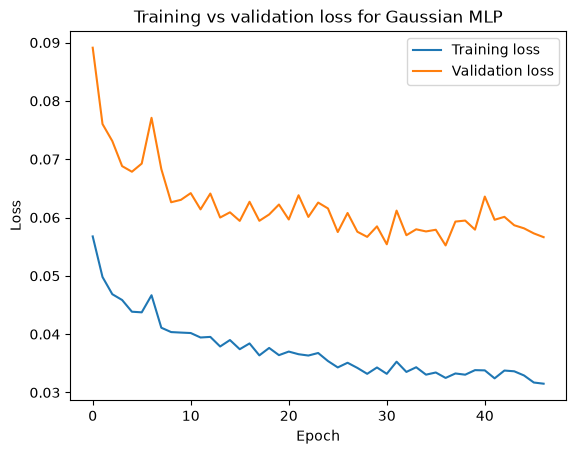

In [7]:
gl_tr, gl_va = ghist[:,0], ghist[:,1]
plt.plot(gl_tr,label='Training loss')
plt.plot(gl_va, label='Validation loss')
plt.title('Training vs validation loss for Gaussian MLP')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.show()

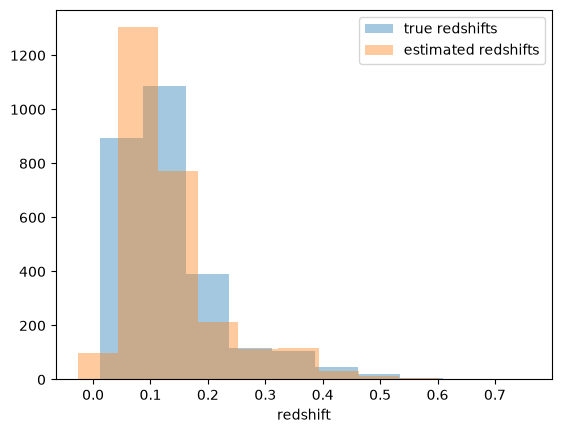

sigma_NMAD: 1.58e-02. outlier fraction: 1.87e-03. mean bias: 1.69e-03


In [8]:
with torch.no_grad():
    z_mse = to_z(g4x(Xs[i_te]).squeeze(1).numpy())
#z_npmse = z_mse.detach().numpy
plt.hist(z_te, label='true redshifts',alpha=0.4)
plt.hist(z_mse, label='estimated redshifts',alpha=0.4)
plt.legend()
plt.xlabel('redshift')
plt.show()

metrics = np.array(photoz_metrics(z_mse, z_te))
print(f'sigma_NMAD: {metrics[0]:.2e}. outlier fraction: {metrics[1]:.2e}. mean bias: {metrics[2]:.2e}')

2. Plot `z_mse` against the true redshift `z_te`. Overplot, mean predicted photo-z in bins of true redshift. Also plot the redshift distribution of training data. Anything interesting? 

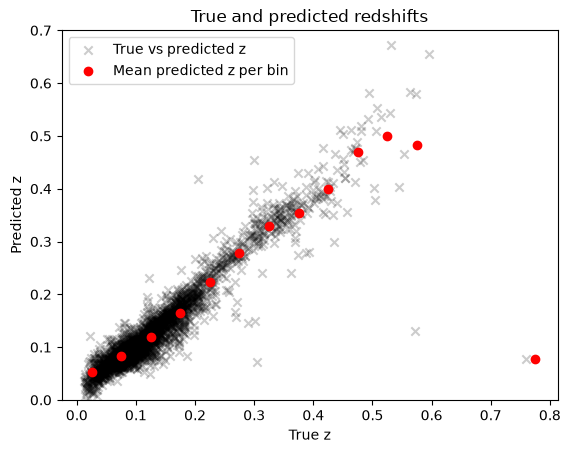

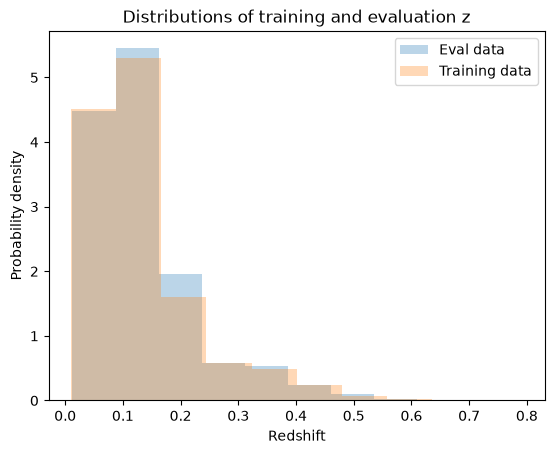

In [9]:
bins = np.linspace(0,0.9,19)
bindices  = np.digitize(z_te,bins)
counts, avgs = [],[]
for i in range(len(bins)):
    mses = z_mse[bindices == i]
    ct = len(mses)
    if ct != 0:
        av = np.mean(mses)
    else: 
        av = np.nan
    counts = counts + [ct]
    avgs = avgs +[av]
binmids = (bins[:-1] + bins[1:])/2
avgs = np.array(avgs)

plt.scatter(z_te,z_mse,color='black',marker = 'x',alpha = 0.2,label='True vs predicted z')
plt.scatter(binmids,avgs[1:],color='red',label='Mean predicted z per bin')
plt.xlabel('True z')
plt.ylabel('Predicted z')
plt.ylim(0,0.7)
plt.legend()
plt.title('True and predicted redshifts')
plt.show()
plt.clf()

z_tr = zspec[i_tr]
plt.hist(z_te, alpha=0.3, label='Eval data', density=True)
plt.hist(z_tr,alpha=0.3,label='Training data',density=True)
plt.xlabel('Redshift')
plt.ylabel('Probability density')
plt.title('Distributions of training and evaluation z')
plt.legend()
plt.show()


3. Instead of Gaussian loss, implement Laplace loss and train a neural network with the same architecture. Plot the loss curves. report the photo-z metrics. How does it compare to the Gaussian loss? Discuss and explain any differences. 

In [10]:
def lloss_fn(pred, y):
    ''' Laplace negative log likelihood (fixed scale) = mean absolute error '''
    return torch.mean(torch.abs(pred.squeeze(1) - y))

torch.manual_seed(1)
l4x = PhotozMLP(sizes=SZ)
lhist, lpoch = fit(l4x, lloss_fn)

with torch.no_grad():
    z_lap = to_z(l4x(Xs[i_te]).squeeze(1).numpy())


sigma_NMAD: 1.49e-02. outlier fraction: 2.62e-03. mean bias: 2.83e-04


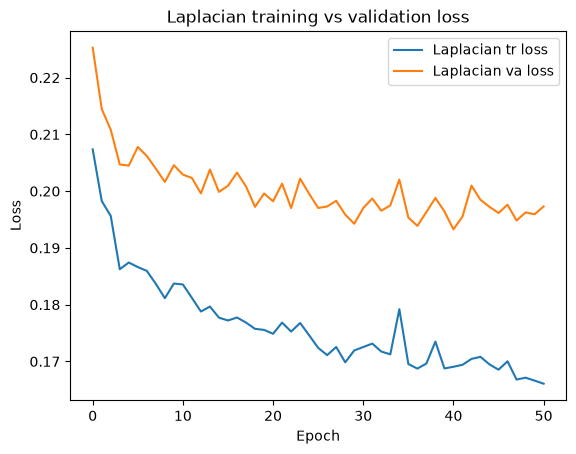

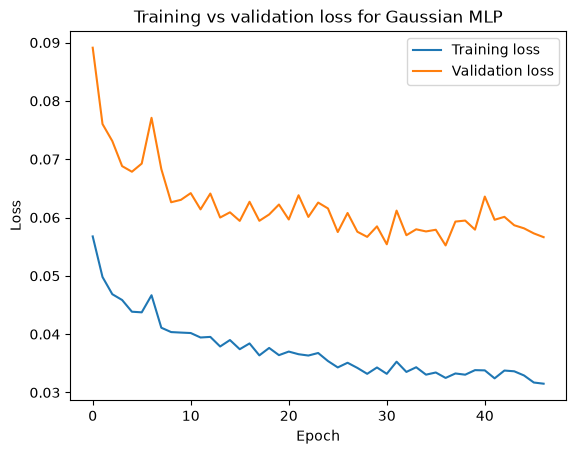

In [11]:
lapmetrics = np.array(photoz_metrics(z_lap, z_te))
print(f'sigma_NMAD: {lapmetrics[0]:.2e}. outlier fraction: {lapmetrics[1]:.2e}. mean bias: {lapmetrics[2]:.2e}')

lap_va, lap_tr = lhist[:,1], lhist[:,0]
plt.plot(lap_tr,label='Laplacian tr loss')
plt.plot(lap_va, label='Laplacian va loss')
plt.title('Laplacian training vs validation loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.show()

plt.clf()
plt.plot(gl_tr,label='Training loss')
plt.plot(gl_va, label='Validation loss')
plt.title('Training vs validation loss for Gaussian MLP')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.show()

4. Now let's also predict the uncertainties as well. Give the network a second output, $\log\sigma$, and let it learn how uncertain each galaxy is
(*heteroscedastic* regression).

The Gaussian negative log-likelihood per galaxy is
$$-\log p(y \mid \mu, \sigma) = \log\sigma + \frac{(y - \mu)^2}{2\sigma^2} + \tfrac12\log 2\pi .$$

*Hint: In this case, $\mu$ and $\log \sigma$ are outputs of the neural network*

Train 5 multiple of these NN with the same architecture but different `torch.manual_seed(seed)` (seed = 0 - 4) and examine their training and photo-z metrics. How do they compare? Anything unusual? Discuss what could be causing this.

In [12]:
def hgloss_fn(pred, y):
    ''' heteroscedastic Gaussian NLL: pred[:,0] = mu, pred[:,1] = log sigma '''
    mu, logsig = pred[:, 0], pred[:, 1]
    return torch.mean(logsig + 0.5 * (y - mu)**2 * torch.exp(-2 * logsig) + 0.5 * np.log(2 * np.pi))

SZ2 = [5, 64, 64, 64, 64, 2]
hg_models, hg_hists, hg_epochs, hg_metrics = [], [], [], []
for seed in range(5):
    torch.manual_seed(seed)
    model = PhotozMLP(sizes=SZ2)
    hist, ep = fit(model, hgloss_fn, seed=seed)
    with torch.no_grad():
        out = model(Xs[i_te])
    mu_z  = to_z(out[:, 0].numpy())
    sig_z = np.exp(out[:, 1].numpy()) * z_sd          # sigma back in redshift units
    m = photoz_metrics(mu_z, z_te)

    hg_models.append(model); hg_hists.append(hist); hg_epochs.append(ep); hg_metrics.append(m)
    print(f'seed {seed}: best epoch {ep:3d}, best val NLL {hist[ep,1]:.3f} | '
          f'sigma_NMAD {m[0]:.2e}, outlier frac {m[1]:.2e}, bias {m[2]:.2e} | median sigma_z {np.median(sig_z):.3f}')



seed 0: best epoch  33, best val NLL -0.090 | sigma_NMAD 1.53e-02, outlier frac 3.00e-03, bias 3.91e-04 | median sigma_z 0.019
seed 1: best epoch  18, best val NLL -0.058 | sigma_NMAD 1.54e-02, outlier frac 2.62e-03, bias -6.89e-04 | median sigma_z 0.019
seed 2: best epoch  17, best val NLL -0.085 | sigma_NMAD 1.54e-02, outlier frac 2.25e-03, bias 1.03e-03 | median sigma_z 0.020
seed 3: best epoch  42, best val NLL -0.074 | sigma_NMAD 1.55e-02, outlier frac 2.25e-03, bias -8.54e-04 | median sigma_z 0.019
seed 4: best epoch  65, best val NLL 0.049 | sigma_NMAD 1.63e-02, outlier frac 3.00e-03, bias 1.72e-05 | median sigma_z 0.020


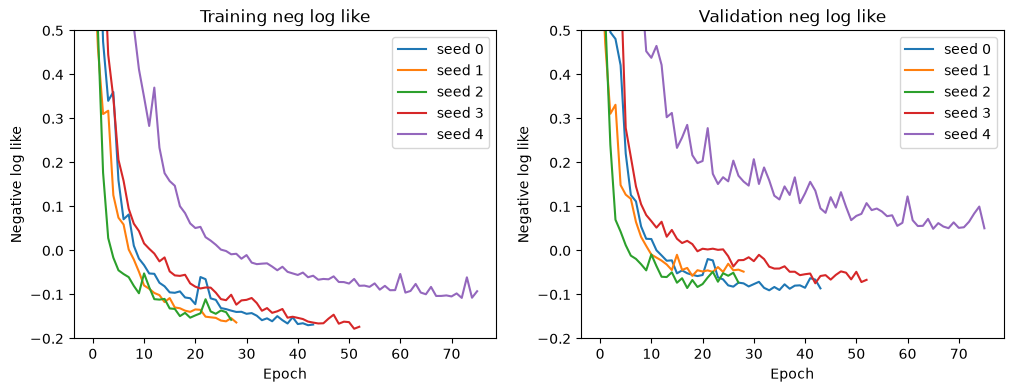

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for seed, hist in enumerate(hg_hists):
    ax[0].plot(hist[:, 0], label=f'seed {seed}')
    ax[1].plot(hist[:, 1], label=f'seed {seed}')
ax[0].set_title('Training neg log like'); ax[1].set_title('Validation neg log like')
for a in ax:
    a.set_xlabel('Epoch'); a.set_ylabel('Negative log like'); a.legend(); a.set_ylim(-0.2,0.5)


plt.show()

5. Train 5 networks again, this time with a heavier tailed likelihood (Student-$t$)

$$\log s + \frac{\nu + 1}{2}\log\Bigl(1 + \frac{(y - \mu)^2}{\nu s^2}\Bigr)$$

with $\nu = 3$ fixed. How does the training and photo-z metrics compare across the 5 seeds? 

In [14]:
NU = 3

def tloss_fn(pred, y, nu=NU):
    ''' Student-t NLL: pred[:,0] = mu, pred[:,1] = log s '''
    mu, logs = pred[:, 0], pred[:, 1]
    r2 = (y - mu)**2 * torch.exp(-2 * logs)                 # (y - mu)^2 / s^2
    return torch.mean(logs + 0.5 * (nu + 1) * torch.log1p(r2 / nu))

t_models, t_hists, t_epochs, t_metrics, t_preds = [], [], [], [], []
for seed in range(5):
    torch.manual_seed(seed)
    model = PhotozMLP(sizes=SZ2)
    hist, ep = fit(model, tloss_fn, seed=seed)
    with torch.no_grad():
        out = model(Xs[i_te])
    mu_z = to_z(out[:, 0].numpy())
    s_z  = np.exp(out[:, 1].numpy()) * z_sd               # scale back in redshift units
    m = photoz_metrics(mu_z, z_te)

    t_models.append(model); t_hists.append(hist); t_epochs.append(ep)
    t_metrics.append(m); t_preds.append((mu_z, s_z))
    print(f'seed {seed}: best epoch {ep:3d}, best val negative log like {hist[ep,1]:.3f} | '
          f'sigma_NMAD {m[0]:.2e}, outlier frac {m[1]:.2e}, bias {m[2]:.2e} | median s_z {np.median(s_z):.3f}')

seed 0: best epoch  37, best val negative log loss -1.134 | sigma_NMAD 1.49e-02, outlier frac 2.62e-03, bias 3.01e-05 | median s_z 0.013
seed 1: best epoch  36, best val negative log loss -1.129 | sigma_NMAD 1.46e-02, outlier frac 2.62e-03, bias -1.14e-03 | median s_z 0.014
seed 2: best epoch  16, best val negative log loss -1.110 | sigma_NMAD 1.46e-02, outlier frac 2.25e-03, bias -1.40e-03 | median s_z 0.014
seed 3: best epoch  31, best val negative log loss -1.119 | sigma_NMAD 1.45e-02, outlier frac 2.62e-03, bias -7.26e-04 | median s_z 0.014
seed 4: best epoch  30, best val negative log loss -1.118 | sigma_NMAD 1.46e-02, outlier frac 1.87e-03, bias -1.86e-03 | median s_z 0.014


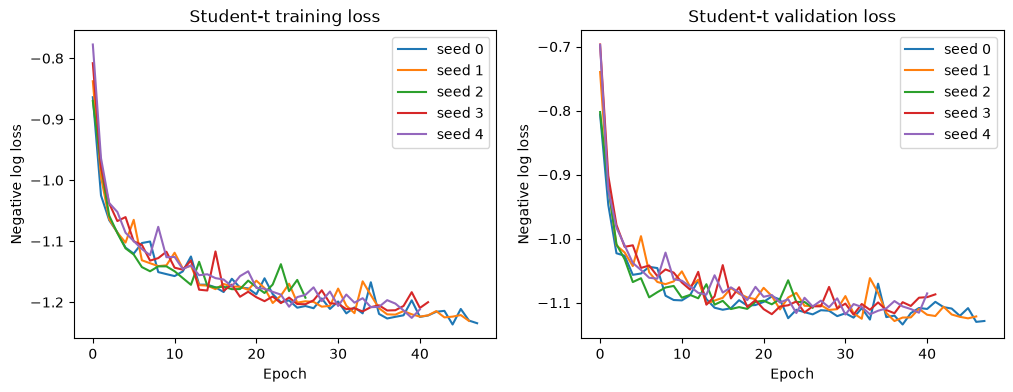

best seed: 0


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for seed, hist in enumerate(t_hists):
    ax[0].plot(hist[:, 0], label=f'seed {seed}')
    ax[1].plot(hist[:, 1], label=f'seed {seed}')
ax[0].set_title('Student-t training NLL'); ax[1].set_title('Student-t validation NLL')
for a in ax:
    a.set_xlabel('Epoch'); a.set_ylabel('Negative log likelihood'); a.legend()
plt.show()

# best network by validation NLL, for the optional question and Q6
best = int(np.argmin([h[e, 1] for h, e in zip(t_hists, t_epochs)]))
t_best = t_models[best]
mu_best, s_best = t_preds[best]
print(f'best seed: {best}')

(Optional): Pick the best network with student-t loss. Where is this network unsure in color-magnitude space? 

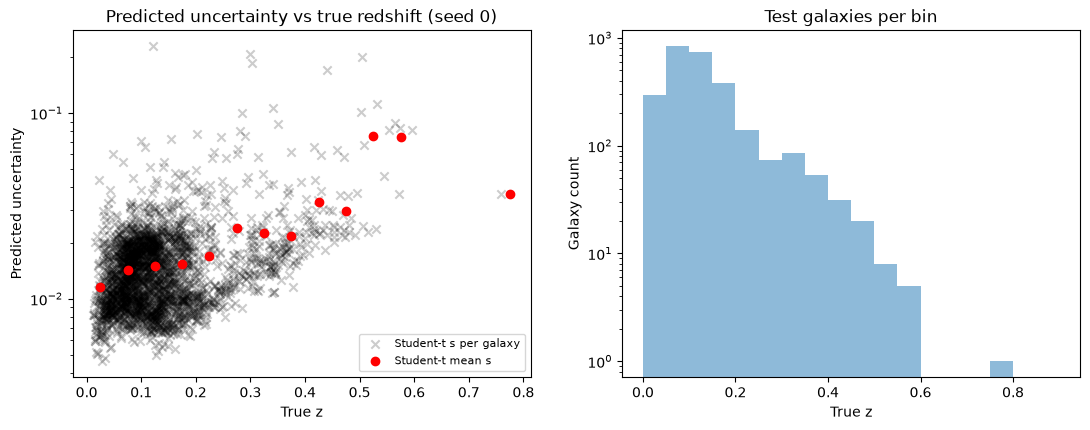

In [16]:
# Student-t seed 0: predictions already stored
mu_t0, s_t0 = t_preds[0]

# Gaussian (Q4) seed 0: sigma wasn't stored, so recompute it
with torch.no_grad():
    out = hg_models[0](Xs[i_te])
mu_g0  = to_z(out[:, 0].numpy())
sig_g0 = np.exp(out[:, 1].numpy()) * z_sd

bins = np.linspace(0, 0.9, 19)
bindices = np.digitize(z_te, bins)
binmids = (bins[:-1] + bins[1:]) / 2

counts, s_avgs, g_avgs, nmads = [], [], [], []
for i in range(1, len(bins)):                     # 1..18 line up with binmids (0 = below bins[0])
    sel = bindices == i
    ct = sel.sum()
    counts.append(ct)
    if ct != 0:
        s_avgs.append(np.mean(s_t0[sel]))
        g_avgs.append(np.mean(sig_g0[sel]))
        r = mu_t0[sel] - z_te[sel]                # actual scatter of the residuals in this bin
        nmads.append(1.4826 * np.median(np.abs(r - np.median(r))))
    else:
        s_avgs.append(np.nan); g_avgs.append(np.nan); nmads.append(np.nan)
s_avgs, g_avgs, nmads, counts = map(np.array, (s_avgs, g_avgs, nmads, counts))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(z_te, s_t0, color='black', marker='x', alpha=0.2, label='Student-t s per galaxy')
ax[0].scatter(binmids, s_avgs, color='red', label='Student-t mean s')
##ax[0].scatter(binmids, g_avgs, color='blue', label=r'Gaussian: mean ')
##ax[0].scatter(binmids, nmads / 1.134, color='orange', marker='s',
##              label='residual NMAD / 1.134 (expected s if calibrated)')
ax[0].set_yscale('log')
ax[0].set_xlabel('True z'); ax[0].set_ylabel('Predicted uncertainty')
ax[0].set_title('Predicted uncertainty vs true redshift (seed 0)')
ax[0].legend(fontsize=8)

ax[1].bar(binmids, counts, width=bins[1] - bins[0], alpha=0.5)
ax[1].set_yscale('log')
ax[1].set_xlabel('True z'); ax[1].set_ylabel('Galaxy count')
ax[1].set_title('Test galaxies per bin')
plt.show()

6. Let's validate the uncertainties using PIT and coverage. Pick the best network with student-t loss. Use `pit_t` function to calculate the PIT and plot the PIT histogram of the test data. Assess the uncertainties.

(Optional): also calculate the coverage for 68% and 95%

KS test vs uniform: D = 0.053, p = 5.22e-07
mean PIT = 0.485 (0.5 if unbiased),  fraction PIT < 0.01 or > 0.99 = 0.007 (0.02 expected)
68% interval: coverage = 0.639
95% interval: coverage = 0.973


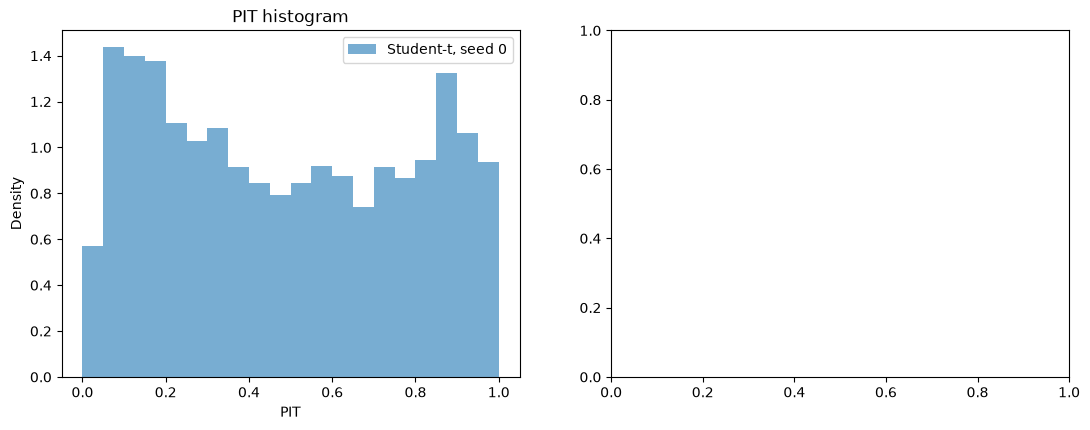

In [17]:
def pit_t(mu, sig, z, nu=3):
    return stats.t.cdf((z - mu) / sig, nu)

pit = pit_t(mu_best, s_best, z_te, nu=NU)

# PIT histogram: flat at 1 if the uncertainties are calibrated
nb = 20
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].hist(pit, bins=nb, range=(0, 1), density=True, alpha=0.6, label=f'Student-t, seed {best}')
##ax[0].axhline(1, color='k', ls='--', label='perfectly calibrated')
# expected Poisson scatter per bin, so you can tell real features from noise
err = np.sqrt(len(pit) / nb) / (len(pit) / nb)
##ax[0].axhspan(1 - err, 1 + err, color='gray', alpha=0.2)
ax[0].set_xlabel('PIT'); ax[0].set_ylabel('Density'); ax[0].set_title('PIT histogram')
ax[0].legend()


ks = stats.kstest(pit, 'uniform')
print(f'KS test vs uniform: D = {ks.statistic:.3f}, p = {ks.pvalue:.2e}')
print(f'mean PIT = {pit.mean():.3f} (0.5 if unbiased),  '
      f'fraction PIT < 0.01 or > 0.99 = {np.mean((pit < 0.01) | (pit > 0.99)):.3f} (0.02 expected)')

# (Optional) coverage of central intervals
for p in (0.68, 0.95):
    half = stats.t.ppf(0.5 + p / 2, NU) * s_best           # half-width of the central p interval
    cov = np.mean(np.abs(z_te - mu_best) <= half)
    print(f'{int(p*100)}% interval: coverage = {cov:.3f}')